# Adversarial validation

- Check how distinguishable train, validation and Kaggle test texts are (3 classes: train / val / test).
- Adversarial analysis uses texts only; H2 below uses source LOC spans for synthetic train/val. `test.csv.locations` is never read.
- Existing manifests are not modified.


## Environment Setup

In [28]:
import gc
import os
import sys
import base64
import random
import subprocess
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from tokenizers import Tokenizer
from scipy.sparse import hstack, csr_matrix
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import confusion_matrix, f1_score, recall_score, roc_auc_score

In [29]:
if "google.colab" in sys.modules:
    from google.colab import userdata
    token = userdata.get("GITHUB_TOKEN")
    root = "/content"
else:
    from kaggle_secrets import UserSecretsClient
    token = UserSecretsClient().get_secret("GITHUB_TOKEN")
    root = "/kaggle/working"

repo = "UA-Locations-NER-Deep-Learning"
branch = "main"
repo_dir = f"{root}/{repo}"

auth = base64.b64encode(f"x-access-token:{token}".encode()).decode()
env = os.environ.copy()
env["GIT_CONFIG_COUNT"] = "1"
env["GIT_CONFIG_KEY_0"] = "http.extraheader"
env["GIT_CONFIG_VALUE_0"] = f"AUTHORIZATION: basic {auth}"

if not os.path.exists(repo_dir):
    subprocess.run(
        ["git", "clone", "-b", branch, f"https://github.com/dkalchenko01/{repo}.git", repo_dir],
        env=env, check=True
    )

print("Repository:", repo_dir)

Repository: /content/UA-Locations-NER-Deep-Learning


In [30]:
sys.path.insert(0, repo_dir)
from src.data_io import get_data_dir, load_manifest, load_data_splits

ENVIRONMENT = "colab" if root == "/content" else "kaggle"
data_dir = Path(get_data_dir(ENVIRONMENT))
splits_dir = Path(repo_dir) / "data" / "splits"
out_dir = Path(root) / "outputs" / "adversarial"
out_dir.mkdir(parents=True, exist_ok=True)

seed = 17
random.seed(seed)
np.random.seed(seed)

print("Data directory:", data_dir)
for path in sorted(data_dir.iterdir()):
    print(path.name, "DIR" if path.is_dir() else "FILE")

Data directory: /root/.cache/kagglehub/competitions/kse-ua-location-extraction-2026
README.md FILE
labeling_sample.csv FILE
ru_geo_dataset.csv FILE
test.csv FILE
uk_geo_dataset.csv FILE
uk_geo_dataset_processed_v1.parquet FILE


## Data Loading

Train and validation come from the fixed manifest. Test contributes only `text_id` and `text`.

In [31]:
manifest = load_manifest(splits_dir)
splits = load_data_splits(ENVIRONMENT, splits_dir)

def collect(split, n_uk, n_ru):
    frames = []
    for source, n in [("uk", n_uk), ("ru", n_ru)]:
        df = splits[f"{source}_{split}"]
        part = manifest[(manifest["source"] == source) & (manifest["split"] == split)]
        group_ids = part.set_index("row_id")["group_id"].reindex(df.index).values
        frame = pd.DataFrame({"text": df["text"].values, "source": source,
                              "group_id": source + "_" + pd.Series(group_ids).astype(str)})
        frames.append(frame.dropna(subset=["text"]).sample(n, random_state=seed))
    return pd.concat(frames, ignore_index=True).assign(label=split)

train_texts = collect("train", 4500, 500)
val_texts = collect("val", 4500, 500)
# Keep full splits for the H2 one-pass audit below.
gc.collect()

test = pd.read_csv(data_dir / "test.csv", usecols=["text_id", "text"])
test_texts = pd.DataFrame({"text": test["text"], "source": "test",
                           "group_id": "test_" + test["text_id"].astype(str), "label": "test"})

texts = pd.concat([train_texts, val_texts, test_texts], ignore_index=True)
texts["text"] = texts["text"].astype(str)
texts["n_chars"] = texts["text"].str.len()
texts["n_lines"] = texts["text"].str.count("\n") + 1

assert len(test_texts) == 477 and texts["n_chars"].gt(0).all()
texts.to_parquet(out_dir / "adversarial_texts.parquet")

texts.groupby("label").agg(rows=("text", "size"), median_chars=("n_chars", "median"),
                           median_lines=("n_lines", "median"), max_chars=("n_chars", "max"))

,rows,median_chars,median_lines,max_chars
label,,,,
test,477,264.0,5.0,3682
train,5000,93.0,1.0,405
val,5000,94.0,1.0,418


In [32]:
texts

,text,source,group_id,label,n_chars,n_lines
0,"Тепер ж відносно пенсії та її розміру, що найб...",uk,uk_328399,train,65,1
1,Ми тепер дорого утримуємо велику ТСК і не дуже...,uk,uk_369545,train,64,1
2,"По-перше, щоб була дуже чітко конструйована ос...",uk,uk_321865,train,56,1
3,При врученні державної нагороди нагородженій о...,uk,uk_980226,train,126,1
4,Значний крок зроблено у сторону диспозитивност...,uk,uk_246803,train,181,1
...,...,...,...,...,...,...
10472,Допомога на відновлення: п’ять громад Київщини...,test,test_472,test,840,11
10473,Пророцтво Стругацьких: незвичайна бактерія Бра...,test,test_473,test,973,9
10474,Із 1 вересня УГКЦ і ПЦУ перейшли на новий церк...,test,test_474,test,345,7
10475,🦇 У Києві з Дніпра виловили іноземця в масці Б...,test,test_475,test,254,7


Text Format Comparison

In [33]:
texts["multiline"] = texts["n_lines"] > 1
texts["has_url"] = texts["text"].str.contains(r"https?://|www\.", case=False, regex=True)
texts["has_hashtag"] = texts["text"].str.contains(r"(?<!\w)#\w+", regex=True)
texts["has_emoji"] = texts["text"].str.contains(r"[\U0001F300-\U0001FAFF]", regex=True)

features = ["multiline", "has_url", "has_hashtag", "has_emoji"]
format_stats = texts.groupby("label")[features].mean().mul(100).round(1)
display(format_stats)

,multiline,has_url,has_hashtag,has_emoji
label,,,,
test,85.1,4.0,3.6,51.8
train,0.0,0.1,0.0,0.0
val,0.0,0.0,0.0,0.0


Test Message Structure

In [34]:
test_lines = test_texts["text"].str.split("\n").explode().str.strip()
test_lines = test_lines[test_lines.str.len() > 0]

line_lengths = test_lines.str.len()
train_lengths = texts.loc[texts["label"] == "train", "n_chars"]
val_lengths = texts.loc[texts["label"] == "val", "n_chars"]

line_stats = pd.DataFrame({
    "train": train_lengths.describe(percentiles=[.5, .9, .95]),
    "val": val_lengths.describe(percentiles=[.5, .9, .95]),
    "test_lines": line_lengths.describe(percentiles=[.5, .9, .95])
}).round(1)

display(line_stats)
print("Non-empty test lines:", len(test_lines))
print("Average lines per test text:", round(len(test_lines) / len(test_texts), 1))

,train,val,test_lines
count,5000.0,5000.0,1871.0
mean,104.7,104.1,99.3
std,48.4,47.6,96.3
min,19.0,22.0,1.0
50%,93.0,94.0,73.0
90%,175.0,172.0,212.0
95%,202.0,198.1,285.5
max,405.0,418.0,992.0


Non-empty test lines: 1871
Average lines per test text: 3.9


In [35]:
length_groups = {
    "train": train_lengths,
    "val": val_lengths,
    "test_messages": texts.loc[texts["label"] == "test", "n_chars"],
    "test_lines": line_lengths
}

thresholds = [200, 400, 500]
length_stats = pd.DataFrame({name: {f"> {t} chars (%)": round((values > t).mean() * 100, 1) for t in thresholds}
    for name, values in length_groups.items()}).T
display(length_stats)

,> 200 chars (%),> 400 chars (%),> 500 chars (%)
train,5.2,0.0,0.0
val,4.7,0.0,0.0
test_messages,57.2,35.0,26.0
test_lines,11.7,1.6,0.8


**Conclusions:**

- Train and validation are similar, but Kaggle test texts are much longer (median: 264 vs. 93–94 characters).

- Test texts often contain multiple lines (85%) and emojis (52%), unlike train/val.

- Individual test lines are shorter (median: 73 characters), but some remain unusually long.

This confirms a distribution shift, which may explain the lower Kaggle score.

## TF-IDF + Logistic Regression

In [36]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
from sklearn.preprocessing import label_binarize

adv = texts[["text", "label", "group_id"]].copy()
adv = adv.dropna().reset_index(drop=True)
adv["text"] = adv["text"].astype(str)
adv["label"] = pd.Categorical(adv["label"], categories=["train", "val", "test"])

assert adv["label"].notna().all()
assert adv["group_id"].notna().all()

print(adv["label"].value_counts())
print("Unique groups:", adv["group_id"].nunique())

label
train    5000
val      5000
test      477
Name: count, dtype: int64
Unique groups: 10457


In [37]:
def make_adv_model():
    return Pipeline([
        ("tfidf", TfidfVectorizer(
            analyzer="char",
            ngram_range=(2, 4),
            min_df=3,
            max_features=50000,
            sublinear_tf=True
        )),
        ("clf", LogisticRegression(
            max_iter=1000,
            class_weight="balanced",
            random_state=seed
        ))
    ])

cv = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=seed)
classes = ["train", "val", "test"]

X = adv["text"].to_numpy()
y = adv["label"].astype(str).to_numpy()
groups = adv["group_id"].to_numpy()

oof_proba = np.zeros((len(adv), len(classes)))
oof_fold = np.full(len(adv), -1)

for fold, (tr_idx, va_idx) in enumerate(cv.split(X, y, groups), 1):
    model = make_adv_model()
    model.fit(X[tr_idx], y[tr_idx])

    oof_proba[va_idx] = model.predict_proba(X[va_idx])[:, [list(model.classes_).index(c) for c in classes]]
    oof_fold[va_idx] = fold

    print(f"Fold {fold}: train={len(tr_idx)}, valid={len(va_idx)}")

Fold 1: train=6984, valid=3493
Fold 2: train=6988, valid=3489
Fold 3: train=6982, valid=3495


Evaluation:

In [38]:
pred_idx = oof_proba.argmax(axis=1)
y_pred = np.array(classes)[pred_idx]

print(classification_report(y, y_pred, labels=classes, digits=3))
print("Confusion matrix:")
print(pd.DataFrame(
    confusion_matrix(y, y_pred, labels=classes),
    index=[f"true_{c}" for c in classes],
    columns=[f"pred_{c}" for c in classes]))

              precision    recall  f1-score   support

       train      0.494     0.494     0.494      5000
         val      0.495     0.501     0.498      5000
        test      0.874     0.769     0.818       477

    accuracy                          0.510     10477
   macro avg      0.621     0.588     0.604     10477
weighted avg      0.512     0.510     0.511     10477

Confusion matrix:
            pred_train  pred_val  pred_test
true_train        2471      2501         28
true_val          2469      2506         25
true_test           57        53        367


In [39]:
test_col = classes.index("test")
is_test = (y == "test").astype(int)

for reference in ["train", "val"]:
    mask = np.isin(y, [reference, "test"])
    auc = roc_auc_score(is_test[mask], oof_proba[mask, test_col])
    print(f"{reference} vs test ROC AUC: {auc:.4f}")

train vs test ROC AUC: 0.9532
val vs test ROC AUC: 0.9530


Adversarial Validation Results

- Train and validation are difficult to distinguish (F1 ≈ 0.5 for each class).

- Kaggle test is clearly different from both (ROC AUC ≈ 0.95).

This confirms a strong distribution shift between train/val and test. Our current validation may not reliably predict Kaggle performance.

### Feature importance

In [40]:
feature_model = make_adv_model()
feature_model.fit(X, y)

vectorizer = feature_model.named_steps["tfidf"]
classifier = feature_model.named_steps["clf"]
features = vectorizer.get_feature_names_out()

print("Features:", len(features))
print("Classes:", classifier.classes_)

Features: 50000
Classes: ['test' 'train' 'val']


In [41]:
test_idx = list(classifier.classes_).index("test")
coef = classifier.coef_[test_idx]

importance = pd.DataFrame({"feature": features, "coefficient": coef})
importance = importance.sort_values("coefficient", ascending=False)

display(importance.head(20))

,feature,coefficient
5229,.,9.740136
2032,ки,2.310047
21449,и.,2.242456
22,\nㅤ,2.071510
49922,️,1.960247
9430,а.,1.904600
40404,у.,1.887605
47382,і.,1.772205
6801,66,1.698465
3917,👀,1.661070


In [42]:
display(importance.tail(20).sort_values("coefficient"))

,feature,coefficient
4517,",",-1.531495
2608,п,-1.045387
30077,о,-0.913125
40006,у,-0.889758
3674,і,-0.834500
3673,і,-0.809641
46991,і,-0.775465
2825,с,-0.774883
1183,в,-0.756034
37558,ст,-0.722912


/tmp/ipykernel_1278/1315172213.py:10: UserWarning: Glyph 128064 (\N{EYES}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1278/1315172213.py:10: UserWarning: Glyph 12644 (\N{HANGUL FILLER}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128064 (\N{EYES}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 12644 (\N{HANGUL FILLER}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


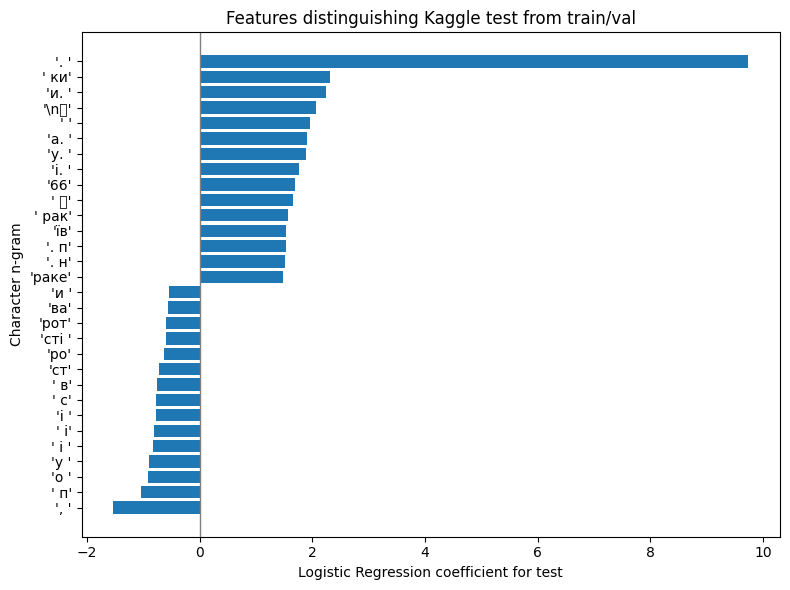

In [43]:
top = pd.concat([importance.head(15), importance.tail(15)]).sort_values("coefficient")
top["feature_display"] = top["feature"].map(repr)

plt.figure(figsize=(8, 6))
plt.barh(top["feature_display"], top["coefficient"])
plt.axvline(0, color="gray", linewidth=1)
plt.xlabel("Logistic Regression coefficient for test")
plt.ylabel("Character n-gram")
plt.title("Features distinguishing Kaggle test from train/val")
plt.tight_layout()
plt.show()

In [44]:
splits_check = splits  # reuse the existing load; no second CSV read
results = []

for split in ["train", "val"]:
    for source in ["uk", "ru"]:
        df = splits_check[f"{source}_{split}"]
        part = manifest[(manifest["source"] == source) & (manifest["split"] == split)]
        group_ids = part.set_index("row_id")["group_id"].reindex(df.index)

        check = pd.DataFrame({
            "group_id": group_ids.to_numpy(),
            "text": df["text"].to_numpy()
        }).dropna()
        check = check.drop_duplicates(["group_id", "text"])
        check["chars"] = check["text"].str.len()

        stats = check.groupby("group_id").agg(
            n_texts=("text", "size"),
            total_chars=("chars", "sum")
        )
        eligible = stats[stats["n_texts"] >= 2]

        results.append({
            "split": split,
            "source": source,
            "groups": len(stats),
            "groups_2plus": len(eligible),
            "groups_200plus_chars": int((eligible["total_chars"] >= 200).sum()),
            "groups_300plus_chars": int((eligible["total_chars"] >= 300).sum()),
            "groups_500plus_chars": int((eligible["total_chars"] >= 500).sum()),
            "median_texts_per_eligible_group": eligible["n_texts"].median()
        })

display(pd.DataFrame(results))
del splits_check

,split,source,groups,groups_2plus,groups_200plus_chars,groups_300plus_chars,groups_500plus_chars,median_texts_per_eligible_group
0,train,uk,802660,3129,1747,773,43,2.0
1,train,ru,93136,6514,4281,1496,99,2.0
2,val,uk,200666,786,418,197,8,2.0
3,val,ru,4922,4911,4909,4891,4737,10.0


In [45]:
for name, s in [("train", train_texts.text), ("val", val_texts.text), ("test", test_texts.text)]:
    print(name,
          s.str.contains(r'\. ').mean(),        # частка текстів з ". "
          s.str.strip().str.endswith('.').mean(),# закінчується крапкою
          s.str.count(r'\.').mean(),             # середня к-сть крапок
          s.str.count(',').mean(),               # коми
          s.str.contains('\u3164').mean(),       # невидимий символ
          s.str.contains('\n').mean(),           # переноси
          s.str.len().describe()[['mean','50%']].values)

train 0.0254 0.9606 1.0134 1.25 0.0 0.0 [104.6744  93.    ]
val 0.0252 0.9588 1.0054 1.2268 0.0 0.0 [104.0784  94.    ]
test 0.5953878406708596 0.3836477987421384 3.6708595387840672 3.5765199161425576 0.06918238993710692 0.8511530398322851 [395.4129979 264.       ]


## Synthetic long texts



In [46]:
from src.eda_scan import parse_spans

min_chars, max_chars = 200, 500
delimiters = ["\n", " ", "\n\n"]
emoji_delimiters = [" 🔥 ", " 📍 ", " 🔔 "]



In [47]:
def make_synthetic(df, groups, random_state=seed):
    rng = random.Random(random_state)
    records = []
    text, spans, row_ids, group_ids = "", [], [], []
    target = rng.randint(min_chars, max_chars)

    def finish():
        nonlocal text, spans, row_ids, group_ids, target
        if len(row_ids) >= 2 and min_chars <= len(text) <= max_chars:
            records.append({
                "text": text, "loc_markers": repr(spans),
                "source_row_ids": row_ids, "source_group_ids": group_ids
            })
        text, spans, row_ids, group_ids = "", [], [], []
        target = rng.randint(min_chars, max_chars)

    for row in df.sample(frac=1, random_state=random_state).itertuples():
        fragment = row.text
        group_id = groups.loc[row.Index]
        if len(fragment) > max_chars:
            continue
        choices = emoji_delimiters if rng.random() < 0.1 else delimiters
        sep = rng.choice(choices) if row_ids else ""
        if group_id in group_ids or len(text) + len(sep) + len(fragment) > max_chars:
            finish()
            sep = ""
        offset = len(text) + len(sep)
        spans.extend((a + offset, b + offset) for a, b in parse_spans(row.loc_markers))
        text += sep + fragment
        row_ids.append(int(row.Index))
        group_ids.append(group_id)
        if len(row_ids) >= 2 and len(text) >= target:
            finish()
    finish()
    return pd.DataFrame(records, columns=[
        "text", "loc_markers", "source_row_ids", "source_group_ids"
    ])



In [48]:
h2_synthetic = {}
results = []

for source in ("uk", "ru"):
    for split in ("train", "val"):
        key = f"{source}_{split}"
        df = splits[key]
        part = manifest[(manifest["source"] == source) & (manifest["split"] == split)]
        groups = part.set_index("row_id")["group_id"]
        synthetic = make_synthetic(df, groups)
        synthetic["text_id"] = [f"syn_{key}_{i}" for i in range(len(synthetic))]
        synthetic["source"] = source
        synthetic["split"] = split
        h2_synthetic[key] = synthetic
        results.append({"source": source, "split": split,
                        "original_rows": len(df), "synthetic_rows": len(synthetic)})

h2_summary = pd.DataFrame(results)
combined = h2_summary.groupby("split")[["original_rows", "synthetic_rows"]].sum().reset_index()
combined["source"] = "combined"
h2_summary = pd.concat([h2_summary, combined], ignore_index=True)
h2_summary["synthetic_pct"] = (
    100 * h2_summary["synthetic_rows"] /
    (h2_summary["original_rows"] + h2_summary["synthetic_rows"])
)
display(h2_summary.round(2))



,source,split,original_rows,synthetic_rows,synthetic_pct
0,uk,train,805983,217428,21.25
1,uk,val,201498,54510,21.29
2,ru,train,100000,31417,23.91
3,ru,val,49369,15628,24.04
4,combined,train,905983,248845,21.55
5,combined,val,250867,70138,21.85


## Fixed synthetic sets



In [49]:
h2_experiments = {"one_pass": h2_synthetic, "synthetic_35": {}, "synthetic_50": {}}

for source in ("uk", "ru"):
    for split in ("train", "val"):
        key = f"{source}_{split}"
        df = splits[key]
        part = manifest[(manifest["source"] == source) & (manifest["split"] == split)]
        groups = part.set_index("row_id")["group_id"]
        batches = [h2_synthetic[key]]
        total = len(batches[0])
        pass_seed = seed + 1
        while total < len(df):
            batch = make_synthetic(df, groups, random_state=pass_seed)
            batches.append(batch)
            total += len(batch)
            pass_seed += 1
        pool = pd.concat(batches, ignore_index=True).iloc[:len(df)].copy()
        pool["text_id"] = [f"syn_{key}_{i}" for i in range(len(pool))]
        pool["source"], pool["split"] = source, split
        for name, fraction in [("synthetic_35", .35), ("synthetic_50", .50)]:
            n = int(np.ceil(len(df) * fraction / (1 - fraction)))
            h2_experiments[name][key] = pool.iloc[:n].copy()

results = []
for name, synthetic_sets in h2_experiments.items():
    for key, synthetic in synthetic_sets.items():
        source, split = key.split("_")
        results.append({"experiment": name, "source": source, "split": split,
                        "original_rows": len(splits[key]), "synthetic_rows": len(synthetic)})
experiment_sizes = pd.DataFrame(results)
combined = experiment_sizes.groupby(["experiment", "split"])[
    ["original_rows", "synthetic_rows"]].sum().reset_index()
combined["source"] = "combined"
experiment_sizes = pd.concat([experiment_sizes, combined], ignore_index=True)
experiment_sizes["synthetic_pct"] = (
    100 * experiment_sizes["synthetic_rows"] /
    (experiment_sizes["original_rows"] + experiment_sizes["synthetic_rows"])
)
display(experiment_sizes.round(2))



,experiment,source,split,original_rows,synthetic_rows,synthetic_pct
0,one_pass,uk,train,805983,217428,21.25
1,one_pass,uk,val,201498,54510,21.29
2,one_pass,ru,train,100000,31417,23.91
3,one_pass,ru,val,49369,15628,24.04
4,synthetic_35,uk,train,805983,433991,35.00
5,synthetic_35,uk,val,201498,108499,35.00
6,synthetic_35,ru,train,100000,53847,35.00
7,synthetic_35,ru,val,49369,26584,35.00
8,synthetic_50,uk,train,805983,805983,50.00
9,synthetic_50,uk,val,201498,201498,50.00


## ROC AUC



In [61]:
def collect_augmented(synthetic_sets, sizes=(4500, 500)):
    frames = []
    for split, original in [("train", train_texts), ("val", val_texts)]:
        for source, n in zip(("uk", "ru"), sizes):
            key = f"{source}_{split}"
            synthetic = synthetic_sets[key]
            fraction = len(synthetic) / (len(splits[key]) + len(synthetic))
            n_synthetic = round(n * fraction)
            short = original[original["source"] == source].sample(n - n_synthetic, random_state=seed).copy()
            short["parent_groups"] = short["group_id"].map(lambda value: [value])
            long = synthetic.sample(n_synthetic, random_state=seed).copy()
            long["label"] = split
            long["group_id"] = long["text_id"]
            long["parent_groups"] = long["source_group_ids"].map(
                lambda values: [f"{source}_{value}" for value in values])
            columns = ["text", "label", "group_id", "parent_groups"]
            frames.extend([short[columns], long[columns]])
    target = test_texts[["text", "label", "group_id"]].copy()
    target["parent_groups"] = target["group_id"].map(lambda value: [value])
    return pd.concat([*frames, target], ignore_index=True)



In [51]:
auc_results = []
for name, synthetic_sets in h2_experiments.items():
    sample = collect_augmented(synthetic_sets)
    X = sample["text"].to_numpy()
    y = sample["label"].to_numpy()
    groups = sample["group_id"].to_numpy()
    parents = sample["parent_groups"].to_numpy()
    test_proba = np.zeros(len(sample))
    fit_sizes = []

    for fold, (tr_idx, va_idx) in enumerate(cv.split(X, y, groups), 1):
        held_out = {group for values in parents[va_idx] for group in values}
        tr_idx = tr_idx[[held_out.isdisjoint(values) for values in parents[tr_idx]]]
        model = make_adv_model()
        model.fit(X[tr_idx], y[tr_idx])
        test_col = list(model.classes_).index("test")
        test_proba[va_idx] = model.predict_proba(X[va_idx])[:, test_col]
        fit_sizes.append(len(tr_idx))
        print(name, "fold", fold, "train:", len(tr_idx), "valid:", len(va_idx))

    row = {"experiment": name, "mean_fit_rows": np.mean(fit_sizes)}
    for reference in ["train", "val"]:
        mask = np.isin(y, [reference, "test"])
        row[f"{reference}_vs_test_auc"] = roc_auc_score((y[mask] == "test").astype(int), test_proba[mask])
    auc_results.append(row)

display(pd.DataFrame(auc_results).round(4))



one_pass fold 1 train: 6924 valid: 3496
one_pass fold 2 train: 6931 valid: 3489
one_pass fold 3 train: 6930 valid: 3492
synthetic_35 fold 1 train: 6865 valid: 3493
synthetic_35 fold 2 train: 6868 valid: 3490
synthetic_35 fold 3 train: 6873 valid: 3494
synthetic_50 fold 1 train: 6814 valid: 3493
synthetic_50 fold 2 train: 6824 valid: 3494
synthetic_50 fold 3 train: 6822 valid: 3490


,experiment,mean_fit_rows,train_vs_test_auc,val_vs_test_auc
0,one_pass,6928.3333,0.9532,0.9532
1,synthetic_35,6868.6667,0.9580,0.9586
2,synthetic_50,6820.0000,0.9562,0.9549


## Synthetic-only vs test

In [62]:
def binary_domain_auc(reference, target=test_texts, folds=None):
    target = target[["text", "group_id"]].copy()
    target["parent_groups"] = target["group_id"].map(lambda value: [value])
    sample = pd.concat([reference, target], ignore_index=True)
    X = sample["text"].to_numpy()
    y = np.r_[np.zeros(len(reference), dtype=int), np.ones(len(target), dtype=int)]
    groups = sample["group_id"].to_numpy()
    parents = sample["parent_groups"].to_numpy()
    proba = np.zeros(len(sample))

    fold_indices = cv.split(X, y, groups) if folds is None else folds
    for tr_idx, va_idx in fold_indices:
        held_out = {group for values in parents[va_idx] for group in values}
        tr_idx = tr_idx[[held_out.isdisjoint(values) for values in parents[tr_idx]]]
        model = make_adv_model()
        model.fit(X[tr_idx], y[tr_idx])
        test_col = list(model.classes_).index(1)
        proba[va_idx] = model.predict_proba(X[va_idx])[:, test_col]
    return roc_auc_score(y, proba)

In [53]:
binary_auc_results = []
for split, original in [("train", train_texts), ("val", val_texts)]:
    reference = original[["text", "group_id"]].copy()
    reference["parent_groups"] = reference["group_id"].map(lambda value: [value])
    binary_auc_results.append({"experiment": "original_only", "split": split,
                               "roc_auc": binary_domain_auc(reference)})

    for name, synthetic_sets in h2_experiments.items():
        frames = []
        for source, n in [("uk", 4500), ("ru", 500)]:
            frame = synthetic_sets[f"{source}_{split}"].sample(n, random_state=seed).copy()
            frame["group_id"] = frame["text_id"]
            frame["parent_groups"] = frame["source_group_ids"].map(
                lambda values: [f"{source}_{value}" for value in values])
            frames.append(frame[["text", "group_id", "parent_groups"]])
        reference = pd.concat(frames, ignore_index=True)
        binary_auc_results.append({"experiment": name + "_synthetic_only", "split": split,
                                   "roc_auc": binary_domain_auc(reference)})
        print(name, split)

display(pd.DataFrame(binary_auc_results).round(4))

one_pass train
synthetic_35 train
synthetic_50 train
one_pass val
synthetic_35 val
synthetic_50 val


,experiment,split,roc_auc
0,original_only,train,0.9465
1,one_pass_synthetic_only,train,0.9733
2,synthetic_35_synthetic_only,train,0.9727
3,synthetic_50_synthetic_only,train,0.9727
4,original_only,val,0.9505
5,one_pass_synthetic_only,val,0.9704
6,synthetic_35_synthetic_only,val,0.9715
7,synthetic_50_synthetic_only,val,0.9713


## Delimiter control

In [54]:
delimiter_controls = {}
for split in ("train", "val"):
    mixed_frames, space_frames = [], []
    for source, n in [("uk", 4500), ("ru", 500)]:
        key = f"{source}_{split}"
        synthetic = h2_synthetic[key].sample(n, random_state=seed)
        reference = synthetic[["text", "text_id"]].rename(columns={"text_id": "group_id"}).copy()
        reference["parent_groups"] = synthetic["source_group_ids"].map(
            lambda values: [f"{source}_{value}" for value in values])
        space_texts = [" ".join(splits[key].loc[row_ids, "text"])
                       for row_ids in synthetic["source_row_ids"]]
        mixed_frames.append(reference)
        space_frames.append(reference.assign(text=space_texts))
    delimiter_controls[split] = {
        "mixed": pd.concat(mixed_frames, ignore_index=True),
        "space": pd.concat(space_frames, ignore_index=True)
    }

In [55]:
delimiter_auc_results = []
for split, variants in delimiter_controls.items():
    for name, reference in variants.items():
        delimiter_auc_results.append({"split": split, "delimiter": name,
                                      "roc_auc": binary_domain_auc(reference)})

display(pd.DataFrame(delimiter_auc_results).round(4))

,split,delimiter,roc_auc
0,train,mixed,0.9733
1,train,space,0.9678
2,val,mixed,0.9704
3,val,space,0.9652


## Binary feature importance

In [56]:
binary_importance = {}
for split, variants in delimiter_controls.items():
    for name, reference in variants.items():
        feature_model = make_adv_model()
        X = pd.concat([reference["text"], test_texts["text"]], ignore_index=True)
        y = np.r_[np.zeros(len(reference), dtype=int), np.ones(len(test_texts), dtype=int)]
        feature_model.fit(X, y)
        vectorizer = feature_model.named_steps["tfidf"]
        classifier = feature_model.named_steps["clf"]
        importance = pd.DataFrame({"feature": vectorizer.get_feature_names_out(),
                                   "coefficient": classifier.coef_[0]})
        importance = importance.sort_values("coefficient", ascending=False)
        binary_importance[(split, name)] = importance
        top = pd.concat([importance.head(15), importance.tail(15)]).copy()
        top["feature"] = top["feature"].map(repr)
        print(split, name, "+ test / - synthetic")
        display(top)

train mixed + test / - synthetic


,feature,coefficient
2343,' ки',2.505851
49357,'їв',2.009695
49841,'️ ',1.982046
24398,'киї',1.897452
24399,'київ',1.897452
23129,'иїв',1.896784
24396,'киє',1.880709
24397,'києв',1.880709
23117,'иєв',1.873552
2355,' киє',1.798746


train space + test / - synthetic


,feature,coefficient
1957,' ки',2.508439
49500,'їв',2.031229
49956,'️ ',2.010307
5245,'.\n',1.916692
24161,'києв',1.910786
24160,'киє',1.910786
24162,'киї',1.907010
24163,'київ',1.907010
22978,'иїв',1.906317
22966,'иєв',1.902943


val mixed + test / - synthetic


,feature,coefficient
2289,' ки',2.495011
49392,'їв',2.049283
49864,'️ ',1.989164
24490,'киє',1.953505
24491,'києв',1.953505
23184,'иєв',1.943395
23198,'иїв',1.920121
24492,'киї',1.917397
24493,'київ',1.917397
2300,' киє',1.867558


val space + test / - synthetic


,feature,coefficient
2019,' ки',2.488791
49416,'їв',2.069918
49955,'️ ',1.995521
24324,'киє',1.984278
24325,'києв',1.984278
23028,'иєв',1.973661
23042,'иїв',1.923323
24326,'киї',1.920530
24327,'київ',1.920530
5293,'.\n',1.906870


## Chunked test vs original texts

In [59]:
from textwrap import wrap

chunk_chars = 200
chunks = []
for row in test_texts.itertuples():
    for line in row.text.split("\n"):
        for chunk in wrap(line, width=chunk_chars, replace_whitespace=False,
                          drop_whitespace=False, break_on_hyphens=False):
            if chunk.strip():
                chunks.append({"text": chunk, "group_id": row.group_id})
test_chunks = pd.DataFrame(chunks)

In [60]:
chunk_auc_results = []
for split, original in [("train", train_texts), ("val", val_texts)]:
    reference = original[["text", "group_id"]].copy()
    reference["parent_groups"] = reference["group_id"].map(lambda value: [value])
    for name, target in [("full_test", test_texts), ("chunked_test", test_chunks)]:
        chunk_auc_results.append({"split": split, "target": name, "target_rows": len(target),
                                  "roc_auc": binary_domain_auc(reference, target=target)})

display(pd.DataFrame(chunk_auc_results).round(4))

,split,target,target_rows,roc_auc
0,train,full_test,477,0.9465
1,train,chunked_test,2132,0.8817
2,val,full_test,477,0.9505
3,val,chunked_test,2132,0.8804


## Equal-size ROC AUC

In [63]:
from textwrap import wrap

chunk_chars = 200
chunks = []
for row in test_texts.itertuples():
    for line in row.text.split("\n"):
        for chunk in wrap(line, width=chunk_chars, replace_whitespace=False,
                          drop_whitespace=False, break_on_hyphens=False):
            if chunk.strip():
                chunks.append({"text": chunk, "group_id": row.group_id})
test_chunks = pd.DataFrame(chunks)

In [64]:
one_chunk = test_chunks.groupby("group_id", sort=False).sample(n=1, random_state=seed)
one_chunk = one_chunk.set_index("group_id")
paired_test = test_texts.loc[test_texts["group_id"].isin(one_chunk.index), ["text", "group_id"]]
paired_test = paired_test.reset_index(drop=True)
one_chunk = one_chunk.loc[paired_test["group_id"]].reset_index()

In [65]:
n = len(paired_test)
n_uk = round(n * .9)
sizes = (n_uk, n - n_uk)

reference = pd.concat([
    train_texts[train_texts["source"] == source].sample(size, random_state=seed)
    for source, size in zip(("uk", "ru"), sizes)
], ignore_index=True)[["text", "group_id"]]
reference["parent_groups"] = reference["group_id"].map(lambda value: [value])
balanced_references = {"original_train": reference}

for name, synthetic_sets in h2_experiments.items():
    augmented = collect_augmented(synthetic_sets, sizes=sizes)
    balanced_references[name] = augmented.loc[
        augmented["label"] == "train", ["text", "group_id", "parent_groups"]
    ].reset_index(drop=True)

X = pd.concat([reference["text"], paired_test["text"]], ignore_index=True).to_numpy()
y = np.r_[np.zeros(n, dtype=int), np.ones(n, dtype=int)]
groups = pd.concat([reference["group_id"], paired_test["group_id"]], ignore_index=True).to_numpy()
balanced_folds = list(cv.split(X, y, groups))

In [66]:
balanced_auc_results = []
for name, reference in balanced_references.items():
    balanced_auc_results.append({
        "train": name, "test": "full_test", "train_rows": len(reference), "test_rows": len(paired_test),
        "synthetic_pct": 100 * reference["group_id"].str.startswith("syn_").mean(),
        "roc_auc": binary_domain_auc(reference, target=paired_test, folds=balanced_folds)
    })

reference = balanced_references["original_train"]
balanced_auc_results.append({
    "train": "original_train", "test": "one_chunk", "train_rows": len(reference), "test_rows": len(one_chunk),
    "synthetic_pct": 0,
    "roc_auc": binary_domain_auc(reference, target=one_chunk, folds=balanced_folds)
})
display(pd.DataFrame(balanced_auc_results).round(4))

,train,test,train_rows,test_rows,synthetic_pct,roc_auc
0,original_train,full_test,477,477,0.0000,0.9224
1,one_pass,full_test,477,477,21.3836,0.9227
2,synthetic_35,full_test,477,477,35.0105,0.9312
3,synthetic_50,full_test,477,477,49.8952,0.9469
4,original_train,one_chunk,477,477,0.0000,0.8402
